The Lane-Emden Equation is:
<h2><center>$\frac{1}{\xi^{2}}\frac{d}{d\xi}\left(\xi^{2}\frac{d\theta}{d\xi}\right) = -\theta^{n}$</center></h2>
Here, $\xi$ is a dimensionless length variable and $\theta$ is a dimensionless density variable, both lying between 0 and 1. <br><br>
The mass of a polytropic star according to the Lane-Emden equation is:
<h4>$M = -4\pi\alpha^{3}\rho_{c}\xi^{2}\frac{d\theta}{d\xi}$</h4>
where,
<h4>$\alpha^{2} = \left[\frac{\left(n+1\right)K}{4\pi G\rho_{c}^{(n-1)/n}}\right]$</h4>
<h4>$\rho_{c}=-\left[\frac{3}{\xi_{1}}\left(\frac{d\theta}{d\xi}\right)_{\xi_{1}}\right]^{-1}\bar{\rho}$</h4> ($\bar{\rho}$ is the average density of the star, $K$ is the constant of proportionality of the polytropic equation of state: $P = K\rho^{1+1/n}$, $n$ is the polytropic index, $\xi_{1}$ is the first root of the solution of the Lane-Emden equation and is related to the stellar radius as: $R = \alpha\xi_{1}$)

We can solve the Lane-Emden equation using a simple numerical iterative approach as:
<h4>$\theta_{i+1} = \theta_{i}+\left(\frac{d\theta}{d\xi}\right)_{i+1}\Delta\xi$</h4>
and
<h4>$\left(\frac{d\theta}{d\xi}\right)_{i+1} = \left(\frac{d\theta}{d\xi}\right)_{i} + \left[\frac{2}{\xi_{i}}\left(\frac{d\theta}{d\xi}\right)_{i}+\theta_{i}^{n}\right]\Delta\xi$</h4>
We can easily get the solutions using these equations and applying the boundary following conditions for the center (starting point) of the star:
$$\xi = 0$$
$$\theta = 1$$
$$\frac{d\theta}{d\xi} = 0$$

#### 1. IMPORTING NECESSARY PACKAGES

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
import pandas as pd
warnings.filterwarnings("ignore")

#### 2. SOLVING THE LANE-EMDEN EQUATION NUMERICALLY FOR SOME $n$ VALUES

First root of θ(ξ) for each n value : 

n = 0 -> ξ ≈ 2.4499999999999917
n = 1 -> ξ ≈ 3.139999999999977
n = 2 -> ξ ≈ 4.3599999999999515
n = 3 -> ξ ≈ 6.9399999999998965


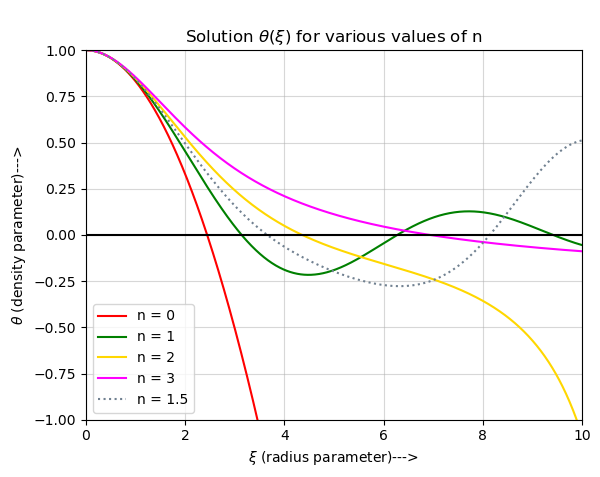

In [2]:
dx = 0.01 # Step length
N = 1000 # Number of integration steps

# Figure customisation part 1
color = ['red','green','gold','fuchsia']

dtheta_dx_lst = []
theta_3 = []

print("First root of θ(ξ) for each n value : \n")

for n in range(4):
    # Starting at the center
    xi = 0.01 # Taking a value close to zero to prevent infinity while dividing
    theta = 1
    dtheta_dx = 0

    theta_sol = []
    xi_sol = []

    # Solving numerically - adding the numerous discrete sums
    for i in range(N):
        dtheta_dx += -((2/xi)*(dtheta_dx)+(theta**n))*dx
        theta += dtheta_dx*dx
        xi += dx
        theta_sol.append(theta)
        xi_sol.append(xi)

    # Check and print the first root
    for j in range(1,len(theta_sol)):
        if (theta_sol[j]<0 and theta_sol[j-1]>=0):
            print(f"n = {n} -> ξ ≈ {xi_sol[j]}")
            break

    if (n==3):
        dtheta_dx_lst.append(dtheta_dx)
        theta_3.append(theta)

    # Plotting the curves
    plt.plot(xi_sol,theta_sol,color=color[n],label=f"n = {n}")

# Getting numerical solution for n = 1.5 separately as fractional n values return complex values
xi1 = 0.01
theta1 = 1
dtheta_dx1 = 0
theta_sol1 = []
xi_sol1 = []
for i in range(N):
    dtheta_dx1 += -((2/xi1)*(dtheta_dx1) + (theta1**1.5)) * dx
    theta1 += dtheta_dx1 * dx
    xi1 += dx
    theta_sol1.append(theta1)
    xi_sol1.append(xi1)
plt.plot(xi_sol1,theta_sol1,color='slategray',linestyle='dotted',label="n = 1.5")

# Figure customisation part 2
plt.xlim(0,10)
plt.ylim(-1,1)
plt.legend()
plt.xlabel('$\\xi$ (radius parameter)--->')
plt.ylabel('$\\theta$ (density parameter)--->')
plt.axhline(color='black')
plt.title("\nSolution $\\theta(\\xi)$ for various values of n")
plt.grid(alpha=0.5)

# Displaying the figure
plt.show()

#### 3. PLOTTING MASS-RADIUS RELATIONSHIP OF THE SUN

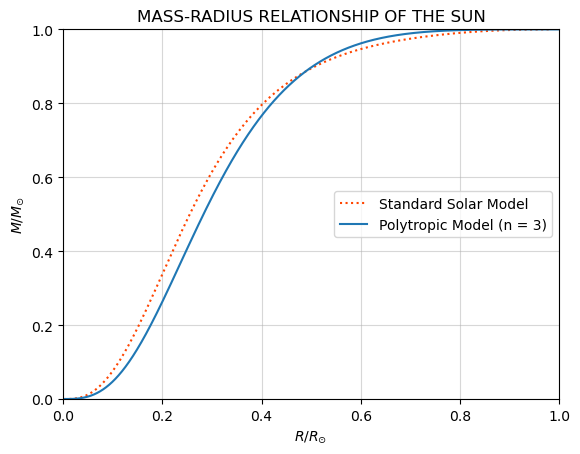

In [3]:
n = 3
N = 10000
dx = 0.001
xi = 0.01       
theta = 1.0
dtheta_dx = 0.0

xi_vals = [xi]
theta_vals = [theta]
dtheta_dx_vals = [dtheta_dx]

for _ in range(N):
    d2theta_dx2 = -((2/xi)*dtheta_dx + theta**n)
    dtheta_dx += d2theta_dx2*dx
    theta += dtheta_dx*dx
    xi += dx

    xi_vals.append(xi)
    theta_vals.append(theta)
    dtheta_dx_vals.append(dtheta_dx)

    if (theta<0):
        break

xi_vals = np.array(xi_vals)
theta_vals = np.array(theta_vals)
dtheta_dx_vals = np.array(dtheta_dx_vals)

# Finding xi1 and derivative at surface
xi1 = xi_vals[-1]
theta_prime_xi1 = dtheta_dx_vals[-1]

# Scaling to Solar Radius
R_sun = 1.0
alpha = R_sun/xi1
r_vals = xi_vals*alpha

# Getting Mass profile from Lane–Emden
m_vals = -(xi_vals**2)*dtheta_dx_vals
m_vals /= m_vals[-1]  # normalizing so surface = 1 Msun


# Importing Standard Solar Model Data
df = pd.read_csv('ssm.dat',sep='\\s+')
mass_ssm = df['M/Msun']
radius_ssm = df['R/Rsun']

# Plotting the graphs
plt.plot(radius_ssm,mass_ssm,color='orangered',linestyle='dotted',label='Standard Solar Model')
plt.plot(r_vals,m_vals,label='Polytropic Model (n = 3)')

# Graph customisation
plt.xlim(0,1)
plt.ylim(0,1)
plt.xlabel('$R/R_{\\odot}$')
plt.ylabel('$M/M_{\\odot}$')
plt.legend(loc='center right')
plt.title("MASS-RADIUS RELATIONSHIP OF THE SUN")
plt.grid(alpha=0.5)

# Displaying the graph
plt.show()

***

*Comparing with a polynomial fit ...*

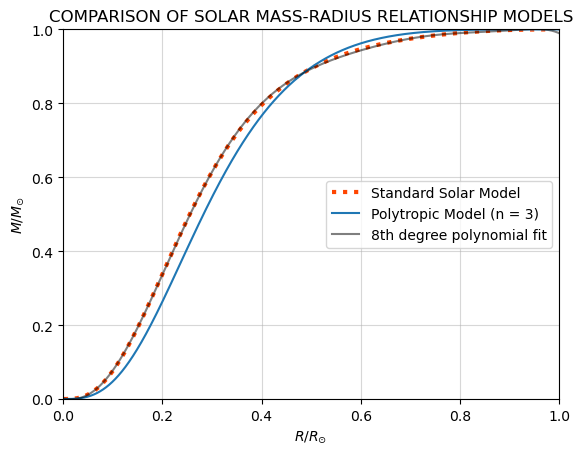

In [4]:
coeffs = [-1.92635261e+02,8.05606659e+02,-1.36053852e+03,1.16645225e+03,-5.09498127e+02, 8.67778976e+01,  
          5.03201981e+00, -2.08477856e-01,1.38524577e-03] # Decreasing order of x starting from 8
poly_x = np.linspace(0,1,1000)
poly_y = np.polyval(coeffs,poly_x)

plt.plot(radius_ssm,mass_ssm,color='orangered',linestyle='dotted',linewidth=3,label='Standard Solar Model')
plt.plot(r_vals,m_vals,label='Polytropic Model (n = 3)')
plt.plot(poly_x,poly_y,color='black',alpha=0.5,label='8th degree polynomial fit')

# Graph customisation
plt.xlim(0,1)
plt.ylim(0,1)
plt.xlabel('$R/R_{\\odot}$')
plt.ylabel('$M/M_{\\odot}$')
plt.legend(loc='center right')
plt.title("COMPARISON OF SOLAR MASS-RADIUS RELATIONSHIP MODELS")
plt.grid(alpha=0.5)

plt.show()

Polynomial fit equation = $-192.635261 x^8 + 805.606659 x^7 - 1360.53852 x^6 + 1166.45225 x^5 - 509.498127 x^4 + 86.7778976 x^3 + 5.03201981 x^2 - 0.208477856 x + 0.00138524577$

***

##### Plotting for Lane-Emden models for density, pressure and temperature.
Density, according to the Lane-Emden Model, is given as:
$$
\rho = \rho_{c}\theta^{n}
$$
Pressure is given as:
$$
P = K\rho_{c}^{(n+1)/n}\theta^{n+1}
$$
Temperature is given as:
$$
T = \frac{\mu m_{H}K\rho_{c}^{1/n}}{k}\theta
$$
According to the SSM, we have: <br>
$\bullet$ $\rho_{c} = 150.5 \hspace{0.1 cm} g\hspace{0.08 cm}cm^{-3}$ <br>
$\bullet$ $P_{c} = 2.338\times 10^{17} \hspace{0.1 cm} N\hspace{0.08 cm}m^{-2}$ <br>
$\bullet$ $T_{c} = 1.548 \times 10^{7} \hspace{0.1 cm} K$

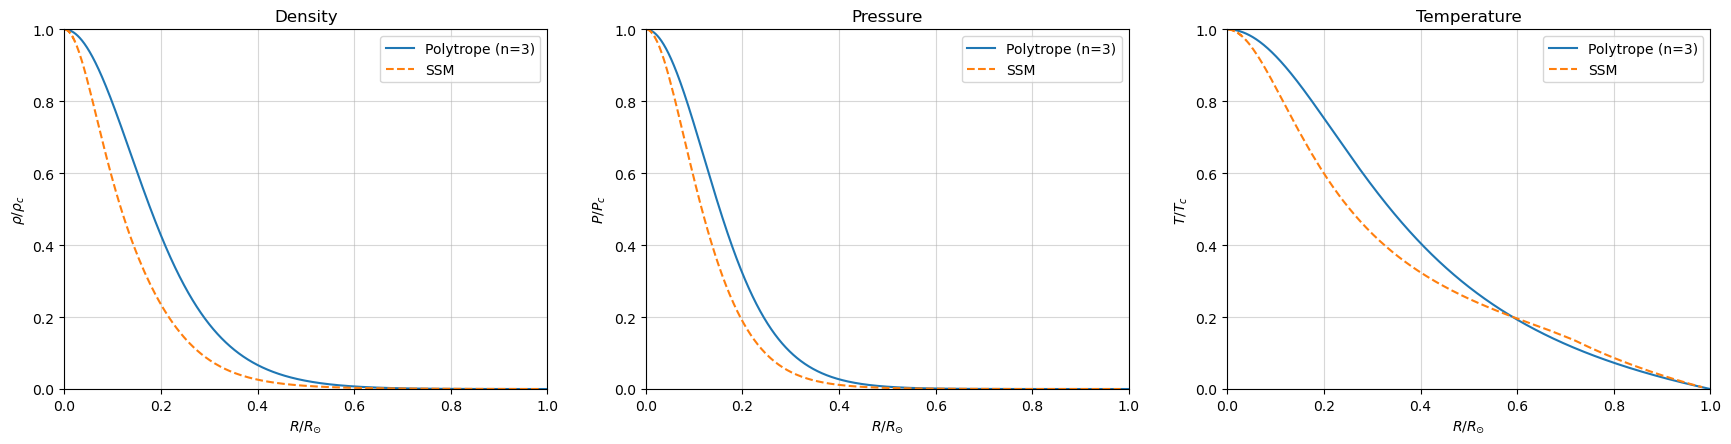

In [5]:
# Values according to the Lane-Emden equation
rho_vals = theta_vals**n # ρ/ρc
P_vals = theta_vals**(n+1) # P/Pc
T_vals = theta_vals # T/Tc

density_ssm = df['Rho']/df['Rho'].iloc[0] # normalized to central density
pressure_ssm = df['P']/df['P'].iloc[0] # normalized to central pressure
temperature_ssm = df['T']/df['T'].iloc[0] # normalized to central temperature

fig, ax = plt.subplots(1,3,figsize=(18,5))
fig.tight_layout(pad=4)

ax[0].plot(r_vals,rho_vals,label="Polytrope (n=3)")
ax[0].plot(radius_ssm,density_ssm,linestyle='--',label="SSM")
ax[0].set_xlim(0,1)
ax[0].set_ylim(0,1)
ax[0].set_xlabel("$R/R_{\\odot}$")
ax[0].set_ylabel("$\\rho/\\rho_c$")
ax[0].set_title("Density")
ax[0].grid(alpha=0.5)
ax[0].legend()

ax[1].plot(r_vals,P_vals,label="Polytrope (n=3)")
ax[1].plot(radius_ssm,pressure_ssm,linestyle='--',label="SSM")
ax[1].set_xlim(0,1)
ax[1].set_ylim(0,1)
ax[1].set_xlabel("$R/R_{\\odot}$")
ax[1].set_ylabel("$P/P_c$")
ax[1].set_title("Pressure")
ax[1].grid(alpha=0.5)
ax[1].legend()

ax[2].plot(r_vals,T_vals,label="Polytrope (n=3)")
ax[2].plot(radius_ssm,temperature_ssm,'--',label="SSM")
ax[2].set_xlim(0,1)
ax[2].set_ylim(0,1)
ax[2].set_xlabel("$R/R_{\\odot}$")
ax[2].set_ylabel("$T/T_c$")
ax[2].set_title("Temperature")
ax[2].grid(alpha=0.5)
ax[2].legend()

plt.show()